# 02_Station-level demand forecasting
Forecasts hourly departures and arrivals for each of the 229 study-area stations. Compares two baselines with LightGBM models trained on a Poisson objective, holds out the last 16 days of September as the test set, and saves the test-period forecasts for the rebalancing optimization.

## 1. Load data

| Name | Source | Role |
|---|---|---|
| `panel` | `data/processed/panel.parquet` | Hourly departures and arrivals per station, with calendar fields and weather |
| `study_stations` | `data/processed/study_stations.parquet` | Station capacity and location |

The forecast is made at midnight for the next day, so every lag feature uses data from the previous day or earlier.

| Period | Dates | Role |
|---|---|---|
| Warm-up | Jun 1 – Jun 7 | Dropped; needed to compute 7-day lag features |
| Train | Jun 8 – Sep 7 | Model fitting |
| Validation | Sep 8 – Sep 14 | Early stopping |
| Test | Sep 15 – Sep 30 | Final evaluation |

In [12]:
import duckdb
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

duckdb.sql("SET enable_progress_bar = false")
processed_dir = '../data/processed'

train_start = '2025-06-08'
valid_start = '2025-09-08'
test_start  = '2025-09-15'

### Register the `panel` and `study_stations` views
Re-run this cell after a kernel restart.

In [13]:
duckdb.sql(f"""
CREATE OR REPLACE VIEW panel AS
SELECT * FROM '{processed_dir}/panel.parquet';

CREATE OR REPLACE VIEW study_stations AS
SELECT * FROM '{processed_dir}/study_stations.parquet';
""")

## 2. Feature engineering

### Build `features`
Lag features are computed per station with window functions. Because the panel has one row for every station-hour, `LAG(x, 24)` is the same hour yesterday and `LAG(x, 168)` the same hour last week.

| Feature | Definition |
|---|---|
| `*_lag_24h` | Same hour, previous day |
| `*_lag_168h` | Same hour, same weekday last week |
| `*_mean_7d_same_hr` | Mean of the same hour over the previous 7 days |
| `*_mean_4w_same_dow` | Mean of the same hour and weekday over the previous 4 weeks |
| `temp_c`, `precip_mm` | Observed hourly weather, used as a stand-in for a weather forecast |

In [14]:
duckdb.sql("""
CREATE OR REPLACE TABLE features AS
SELECT p.station_id,
       p.hour_ts,
       p.date,
       p.hr,
       p.dow,
       p.day_type,
       p.temp_c,
       p.precip_mm,
       s.capacity,
       s.lat,
       s.lng,
       p.departures,
       p.arrivals,
       LAG(p.departures, 24)  OVER w_station  AS dep_lag_24h,
       LAG(p.departures, 168) OVER w_station  AS dep_lag_168h,
       AVG(p.departures)      OVER w_same_hr  AS dep_mean_7d_same_hr,
       AVG(p.departures)      OVER w_same_dow AS dep_mean_4w_same_dow,
       LAG(p.arrivals, 24)    OVER w_station  AS arr_lag_24h,
       LAG(p.arrivals, 168)   OVER w_station  AS arr_lag_168h,
       AVG(p.arrivals)        OVER w_same_hr  AS arr_mean_7d_same_hr,
       AVG(p.arrivals)        OVER w_same_dow AS arr_mean_4w_same_dow
FROM panel p
JOIN study_stations s USING (station_id)
WINDOW w_station  AS (PARTITION BY p.station_id ORDER BY p.hour_ts),
       w_same_hr  AS (PARTITION BY p.station_id, p.hr ORDER BY p.date
                      ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING),
       w_same_dow AS (PARTITION BY p.station_id, p.dow, p.hr ORDER BY p.date
                      ROWS BETWEEN 4 PRECEDING AND 1 PRECEDING)
""")

### Load into pandas and split
`station_id` and `day_type` become categorical columns so LightGBM can split on them directly.

In [15]:
df = duckdb.sql(f"""
SELECT *
FROM features
WHERE date >= '{train_start}'
ORDER BY station_id, hour_ts
""").df()

df['station_id'] = df['station_id'].astype('category')
df['day_type'] = df['day_type'].astype('category')

train = df[df['date'] <  pd.Timestamp(valid_start)]
valid = df[(df['date'] >= pd.Timestamp(valid_start)) & (df['date'] < pd.Timestamp(test_start))]
test  = df[df['date'] >= pd.Timestamp(test_start)].copy()

pd.DataFrame({
    'rows':  [len(train), len(valid), len(test)],
    'first': [train['date'].min(), valid['date'].min(), test['date'].min()],
    'last':  [train['date'].max(), valid['date'].max(), test['date'].max()],
}, index=['train', 'valid', 'test'])

,rows,first,last
train,505632,2025-06-08,2025-09-07
valid,38472,2025-09-08,2025-09-14
test,87936,2025-09-15,2025-09-30


**Key findings: feature engineering**
- Train has 505,632 rows (92 days × 24 hours × 229 stations), validation 38,472 (7 days) and test 87,936 (16 days), with no gaps.
- The test period starts one week after training ends, so every lag feature in the test set uses observed data only.

## 3. Baselines

### Seasonal naive and historical average
- **Seasonal naive:** the same hour last week (`*_lag_168h`).
- **Historical average:** the mean for the same station, hour and day type over all pre-test data (train + validation).

In [16]:
targets = ['departures', 'arrivals']
pre_test = pd.concat([train, valid])

hist_avg = (
    pre_test
    .groupby(['station_id', 'hr', 'day_type'], observed=True)[targets]
    .mean()
    .add_suffix('_hist')
    .reset_index()
)
test = test.merge(hist_avg, on=['station_id', 'hr', 'day_type'], how='left')

test['departures_naive'] = test['dep_lag_168h']
test['arrivals_naive']   = test['arr_lag_168h']

## 4. LightGBM

### Train one model per target
Poisson objective, because hourly counts are non-negative and overdispersed. Training stops when the validation Poisson loss has not improved for 100 rounds.

In [17]:
features = [
    'station_id', 'hr', 'dow', 'day_type', 'temp_c', 'precip_mm', 'capacity', 'lat', 'lng',
    'dep_lag_24h', 'dep_lag_168h', 'dep_mean_7d_same_hr', 'dep_mean_4w_same_dow',
    'arr_lag_24h', 'arr_lag_168h', 'arr_mean_7d_same_hr', 'arr_mean_4w_same_dow',
]

params = {
    'objective':        'poisson',
    'learning_rate':    0.05,
    'num_leaves':       63,
    'min_data_in_leaf': 50,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq':     1,
    'seed':             42,
    'verbose':          -1,
}

models = {}
for target in targets:
    dtrain = lgb.Dataset(train[features], train[target])
    dvalid = lgb.Dataset(valid[features], valid[target], reference=dtrain)
    models[target] = lgb.train(
        params,
        dtrain,
        num_boost_round=3000,
        valid_sets=[dvalid],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    test[f'{target}_lgbm'] = models[target].predict(test[features], num_iteration=models[target].best_iteration)
    print(f'{target}: best iteration {models[target].best_iteration}')

departures: best iteration 457
arrivals: best iteration 392


### Feature importance
Total gain per feature for the departures model.

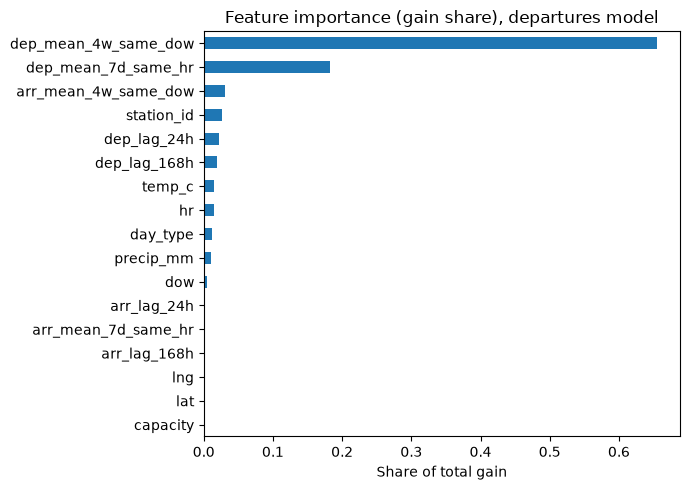

In [18]:
importance = (
    pd.Series(models['departures'].feature_importance('gain'), index=features)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(7, 5))
(importance / importance.sum()).plot.barh(ax=ax)
ax.set_title('Feature importance (gain share), departures model')
ax.set_xlabel('Share of total gain')
plt.tight_layout()
plt.show()

## 5. Evaluation

### Hourly accuracy on the test set
MAE and RMSE are in trips per station-hour. WAPE is total absolute error divided by total actual trips, so it is comparable across targets.

In [19]:
def score(y, yhat):
    err = y - yhat
    return {
        'MAE':      np.abs(err).mean(),
        'RMSE':     np.sqrt((err ** 2).mean()),
        'WAPE_pct': 100 * np.abs(err).sum() / y.sum(),
    }

methods = {'naive': 'Seasonal naive', 'hist': 'Historical average', 'lgbm': 'LightGBM'}
rows = []
for target in targets:
    for suffix, label in methods.items():
        rows.append({'target': target, 'method': label, **score(test[target], test[f'{target}_{suffix}'])})

pd.DataFrame(rows).round(2)

,target,method,MAE,RMSE,WAPE_pct
0,departures,Seasonal naive,4.25,7.00,41.22
1,departures,Historical average,3.72,6.19,36.05
2,departures,LightGBM,3.36,5.58,32.57
3,arrivals,Seasonal naive,4.13,7.00,40.93
4,arrivals,Historical average,3.71,6.24,36.73
5,arrivals,LightGBM,3.29,5.54,32.57


### Morning-peak net flow accuracy
The optimization uses each station's weekday 7–10 AM net flow (arrivals − departures). This aggregates hourly forecasts to one value per station per weekday and reports the MAE in bikes.

In [20]:
am = test[(test['day_type'] == 'weekday') & test['hr'].between(7, 9)]

am_net = am.groupby(['station_id', 'date'], observed=True).agg(
    actual=('arrivals', 'sum'),
    actual_dep=('departures', 'sum'),
    **{f'{s}_arr': (f'arrivals_{s}', 'sum') for s in methods},
    **{f'{s}_dep': (f'departures_{s}', 'sum') for s in methods},
)
am_net['actual'] = am_net['actual'] - am_net['actual_dep']

pd.DataFrame([
    {'method': label,
     'MAE_bikes': np.abs(am_net['actual'] - (am_net[f'{s}_arr'] - am_net[f'{s}_dep'])).mean()}
    for s, label in methods.items()
]).round(2)

,method,MAE_bikes
0,Seasonal naive,11.47
1,Historical average,10.99
2,LightGBM,9.56


### Forecast vs. actual for one office station
Hourly departures at E 47 St & Park Ave, the station with the largest morning inflow, over the first test week.

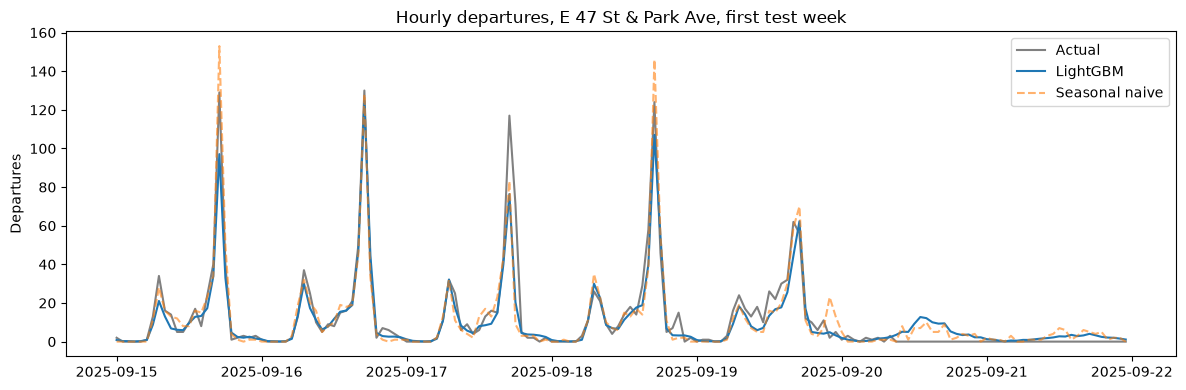

In [21]:
station_name = 'E 47 St & Park Ave'
station_id = duckdb.sql(f"""
SELECT station_id FROM study_stations WHERE name = '{station_name}'
""").fetchall()[0][0]

week = test[(test['station_id'] == station_id)
            & (test['date'] < pd.Timestamp(test_start) + pd.Timedelta(days=7))]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week['hour_ts'], week['departures'], color='gray', label='Actual')
ax.plot(week['hour_ts'], week['departures_lgbm'], color='tab:blue', label='LightGBM')
ax.plot(week['hour_ts'], week['departures_naive'], color='tab:orange', alpha=0.6, ls='--', label='Seasonal naive')
ax.set_title(f'Hourly departures, {station_name}, first test week')
ax.set_ylabel('Departures')
ax.legend()
plt.tight_layout()
plt.show()

**Key findings: evaluation**
- LightGBM is the most accurate method for both targets. For departures, test MAE is 3.36 trips per station-hour vs. 3.72 for the historical average (−10%) and 4.25 for the seasonal naive (−21%). Arrivals show the same pattern (3.29 vs. 3.71 and 4.13).
- Hourly WAPE is 32.6% for LightGBM, against 36–41% for the baselines. Station-hour counts are small and noisy, so relative errors at this level stay high for every method.
- On the metric the optimization uses, weekday 7–10 AM net flow per station, LightGBM's MAE is 9.6 bikes per station-day vs. 11.0 for the historical average (−13%) and 11.5 for the seasonal naive (−17%).
- The model relies mainly on recent same-hour history: the 4-week same-weekday mean holds 65% of the gain and the 7-day same-hour mean 18%. Weather and calendar features add 1–2% each; capacity and coordinates add almost nothing, because `station_id` already identifies each station.
- At E 47 St & Park Ave, LightGBM tracks the daily shape but under-predicts the sharpest evening spikes (e.g. 117 actual vs. about 70 forecast on Sep 17). The seasonal naive overshoots after a spike the previous week.
- The station records zero departures on Sep 20–21 while every method forecasts some activity, which suggests the station was out of service that weekend. Outages like this are not in the features and add irreducible error.

## 6. Save outputs

### Save test-period forecasts
Writes actual and LightGBM-forecast departures and arrivals for every station-hour in the test period, for the optimization notebook.

In [22]:
forecasts = test[['station_id', 'hour_ts', 'date', 'hr', 'day_type',
                  'departures', 'arrivals', 'departures_lgbm', 'arrivals_lgbm']].copy()
forecasts['station_id'] = forecasts['station_id'].astype(str)
forecasts['day_type'] = forecasts['day_type'].astype(str)

duckdb.sql(f"""
COPY forecasts TO '{processed_dir}/forecasts.parquet' (FORMAT PARQUET)
""")